In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
from Minimal_Model_2D import *
import Minimal_model_1D_1sub as M_1sub
import Minimal_Model_1D as M1
import time

np.set_printoptions(threshold=sys.maxsize)

In [2]:
NSM = 1          # in nm
MY = 2              # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0          # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

MEFF = 0.023

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

MU_const = 0.8 + OMEGA/2

#ALPHAT = 50
#ALPHAT = 40
ALPHAT = 0

first subband energy = 1.3263440267269595 
 second subband energy = 2.652688053453919


plotting band spectrum

In [3]:
NUM = 501
KX = np.linspace(-np.pi/10,np.pi/10,NUM)
Ep = np.empty((KX.shape[0], N))

for i in range(KX.shape[0]):

    Fli = M_1sub.Model(N ,NSM, NSC, AX ,OMEGA, ALPHAT, DELTA, MEFF,  MU_const,  phi=PHI, px=True, kx0=KX[i])

    Hli = Fli.H_p()

    Eli, Vli = eigsh(Hli ,k=N,sigma=0, return_eigenvectors=True)
        
    #Eli = np.sort(Eli)

    #print(Eli.shape)    
    #Eli = np.sort(Eli)
    
    Ep[i,:] = Eli

    if i%5 == 0:
        print(i)

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
150
155
160
165
170
175
180
185
190
195
200
205
210
215
220
225
230
235
240
245
250
255
260
265
270
275
280
285
290
295
300
305
310
315
320
325
330
335
340
345
350
355
360
365
370
375
380
385
390
395
400
405
410
415
420
425
430
435
440
445
450
455
460
465
470
475
480
485
490
495
500


In [4]:
Ep.shape

(501, 5)

In [5]:
print(Ep[0,:])

[ 161.48974315 1366.04642088  161.48974315 1366.04642088 3315.06006682]


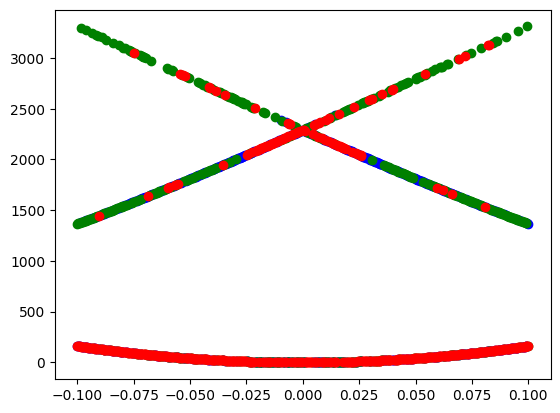

In [6]:
plt.scatter(KX/np.pi,Ep[:,0], color='blue')
plt.scatter(KX/np.pi,Ep[:,1], color = 'green')
plt.scatter(KX/np.pi,Ep[:,2], color = 'red')



In [7]:
NUM = 501
KX = np.linspace(-np.pi/10,np.pi/10,NUM)
EpM = np.empty((KX.shape[0], N))

for i in range(KX.shape[0]):

    Fli = M1.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, px=True)
            
    Hli = Fli.HN(so = 'li', kx=KX[i])

    Eli = eigsh(Hli ,k=N,sigma=0, return_eigenvectors=False)
        
    Eli = np.sort(Eli)

    #print(Eli.shape)    
    #Eli = np.sort(Eli)
    
    EpM[i,:] = Eli

    if i%5 == 0:

        print(i)

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
150
155
160
165
170
175
180
185
190
195
200
205
210
215
220
225
230
235
240
245
250
255
260
265
270
275
280
285
290
295
300
305
310
315
320
325
330
335
340
345
350
355
360
365
370
375
380
385
390
395
400
405
410
415
420
425
430
435
440
445
450
455
460
465
470
475
480
485
490
495
500


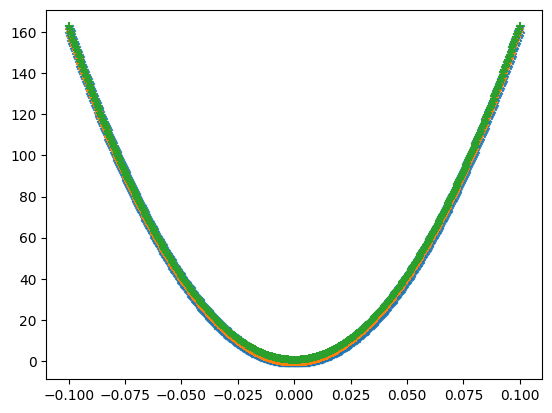

In [8]:
plt.scatter(KX/np.pi,EpM[:,0], marker='x')
plt.scatter(KX/np.pi,EpM[:,1], marker= '+')
plt.scatter(KX/np.pi,EpM[:,2], marker= '+')

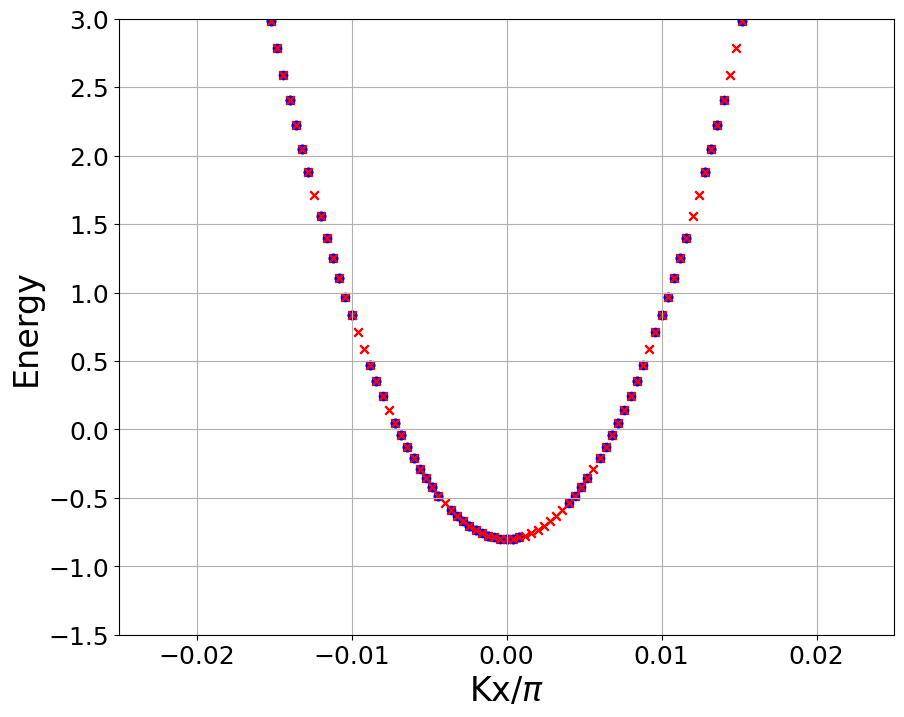

In [20]:
#alpha = 50 
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
plt.scatter(KX/np.pi,Ep[:,1], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
plt.scatter(KX/np.pi,EpM[:,1], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.ylim(ymin=-1.5)
plt.ylim(ymax=3)

plt.xlim(xmax = 0.025,xmin=-0.025)

#plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

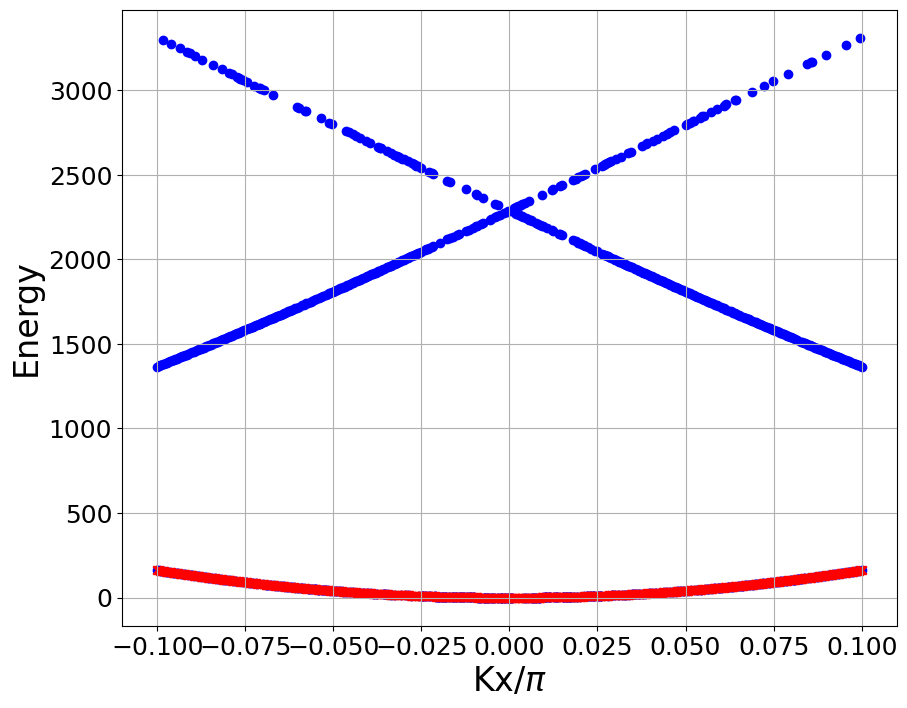

In [19]:
#alpha = 40 
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
plt.scatter(KX/np.pi,Ep[:,1], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
plt.scatter(KX/np.pi,EpM[:,1], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

#plt.ylim(ymin=-1.5)
#plt.ylim(ymax=3)

#plt.xlim(xmax = 0.025,xmin=-0.025)

#plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

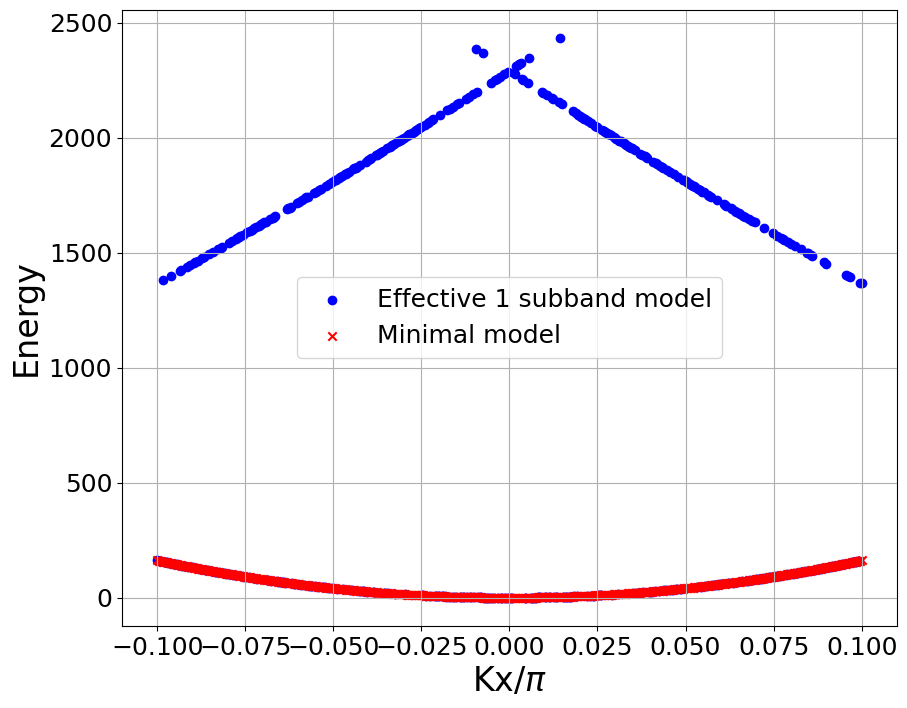

In [17]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

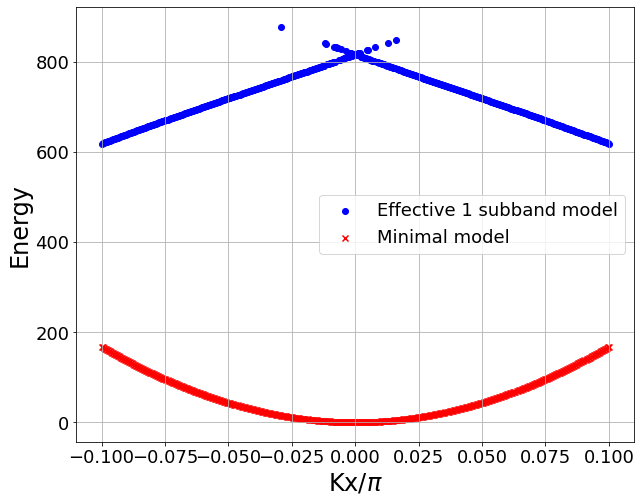

In [74]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,2], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,2], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

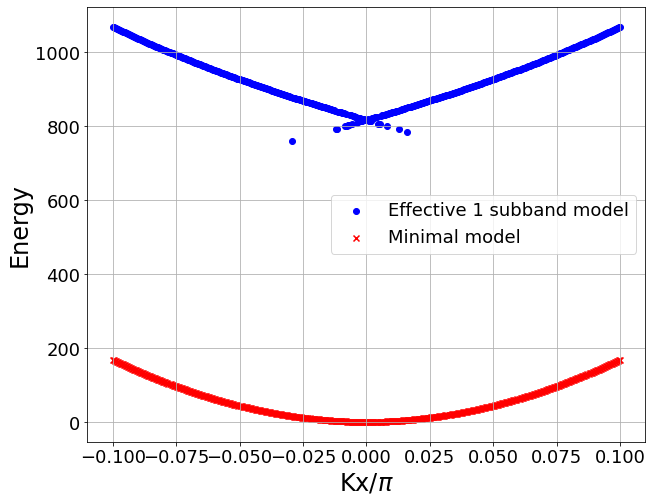

In [75]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,3], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,3], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')
plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

#### non zero spin orbit , ly = 75

In [71]:
NSM = 3          # in nm
MY = 2              # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0          # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

MEFF = 0.023

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 3
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2
MU_SM =  0.8 + OMEGA/2

#MU_const = 0

ALPHAT = 20


first subband energy = 2.3579449364034835 
 second subband energy = 4.715889872806967


In [23]:
NUM = 51
KX = np.linspace(-np.pi/6,np.pi/6,NUM)
Ep = np.empty((KX.shape[0], N))

for i in range(KX.shape[0]):

    Fli = M_1sub.Model(N ,NSM, NSC, AX ,OMEGA, ALPHAT, DELTA, MEFF,  MU_const,  phi=PHI, px=True, kx0=KX[i])

    Hli = Fli.H_p()

    Eli, Vli = eigsh(Hli ,k=N,sigma=0, return_eigenvectors=True)
        
    #Eli = np.sort(Eli)

    #print(Eli.shape)    
    #Eli = np.sort(Eli)
    
    Ep[i,:] = Eli

    if i%5 == 0:
        print(i)

0
5
10
15
20
25
30
35
40
45
50


In [24]:
NUM = 51
KX = np.linspace(-np.pi/6,np.pi/6,NUM)
EpM = np.empty((KX.shape[0], N))

for i in range(KX.shape[0]):

    Fli = M1.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, px=True)
            
    Hli = Fli.HN(so = 'li', kx=KX[i])

    Eli = eigsh(Hli ,k=N,sigma=0, return_eigenvectors=False)
        
    Eli = np.sort(Eli)

    #print(Eli.shape)    
    #Eli = np.sort(Eli)
    
    EpM[i,:] = Eli

    if i%5 == 0:

        print(i)

0
5
10
15
20
25
30
35
40
45
50


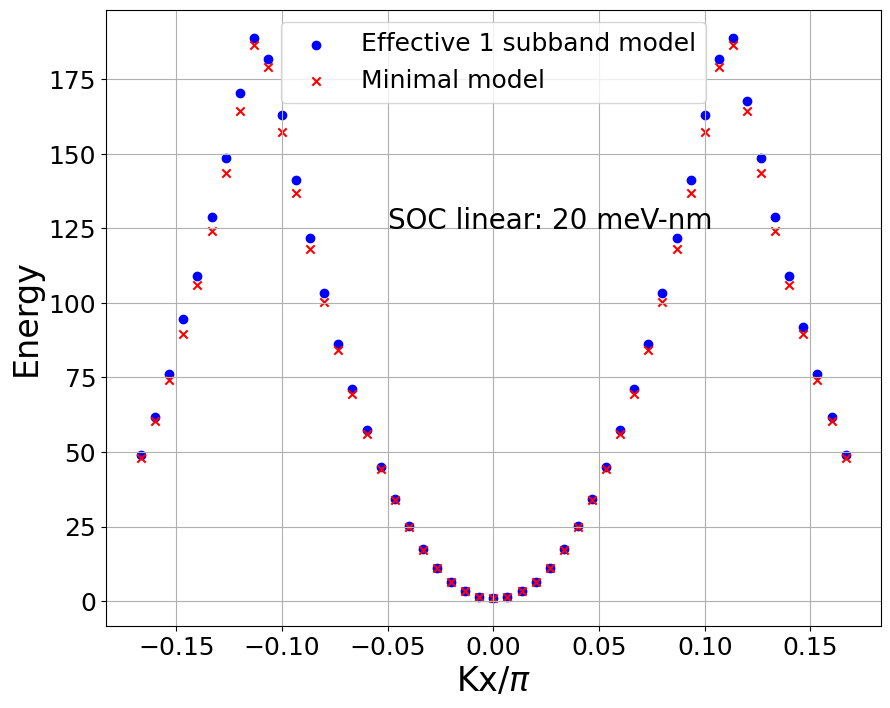

In [39]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')


# Print parameters on the plot
plt.text(-0.05,125, f'SOC linear: {ALPHAT} meV-nm', fontsize=20)

plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

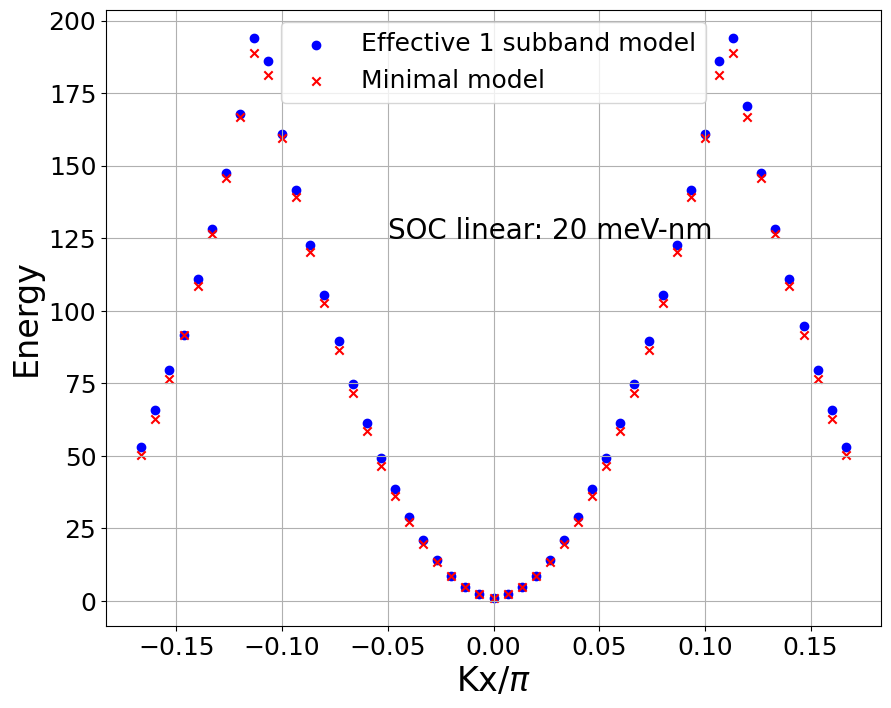

In [40]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,1], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,1], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')


# Print parameters on the plot
plt.text(-0.05,125, f'SOC linear: {ALPHAT} meV-nm', fontsize=20)

plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

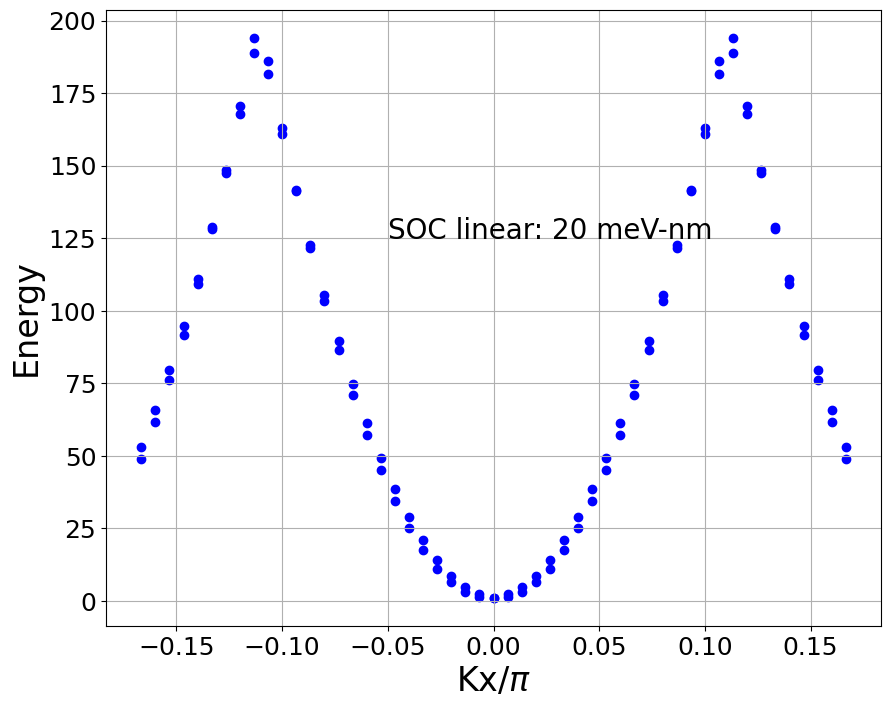

In [41]:
#alpha = 40 
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
plt.scatter(KX/np.pi,Ep[:,1], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

#plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,1], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')



# Print parameters on the plot
plt.text(-0.05,125, f'SOC linear: {ALPHAT} meV-nm', fontsize=20)

#plt.ylim(ymin=-1.5)
#plt.ylim(ymax=3)

#plt.xlim(xmax = 0.025,xmin=-0.025)

#plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

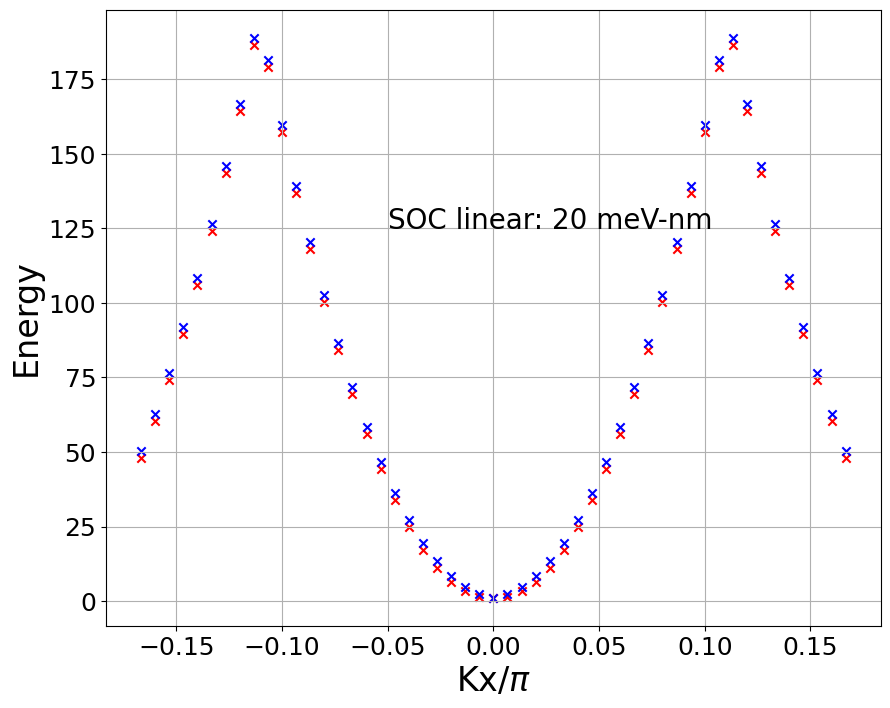

In [42]:
#alpha = 40 
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

#plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,1], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
plt.scatter(KX/np.pi,EpM[:,1], marker='x', color='blue')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

#plt.ylim(ymin=-1.5)
#plt.ylim(ymax=3)

#plt.xlim(xmax = 0.025,xmin=-0.025)


# Print parameters on the plot
plt.text(-0.05,125, f'SOC linear: {ALPHAT} meV-nm', fontsize=20)

#plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

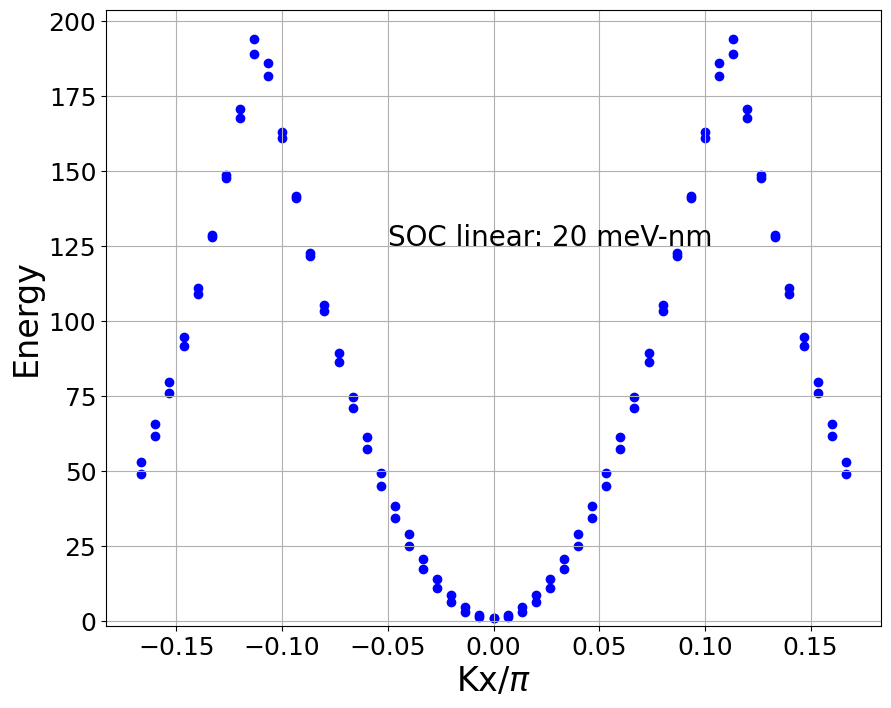

In [43]:
#alpha = 0 
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
plt.scatter(KX/np.pi,Ep[:,1], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

#plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,1], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.ylim(ymin=-1.5)
#plt.ylim(ymax=3)

#plt.xlim(xmax = 0.025,xmin=-0.025)

# Print parameters on the plot
plt.text(-0.05,125, f'SOC linear: {ALPHAT} meV-nm', fontsize=20)

#plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

In [132]:
LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2
MU_SM =  0.8 + OMEGA/2

MU_const = 0.8 + OMEGA/2


ALPHAT = 31             ### for 75 nm , 32 meV is where the band spectrum of 1d effective model breaks down 

NUM = 201
KX = np.linspace(-np.pi/6,np.pi/6,NUM)
Ep = np.empty((KX.shape[0], N))

for i in range(KX.shape[0]):

    Fli = M_1sub.Model(N ,NSM, NSC, AX ,OMEGA, ALPHAT, DELTA, MEFF,  MU_const,  phi=PHI, px=True, kx0=KX[i])

    Hli = Fli.H_p()

    Eli, Vli = eigsh(Hli ,k=N,sigma=0, return_eigenvectors=True)
        
    #Eli = np.sort(Eli)

    #print(Eli.shape)    
    Eli = np.sort(Eli)
    
    Ep[i,:] = Eli

    if i%5 == 0:
        print(i)



KX = np.linspace(-np.pi/6,np.pi/6,NUM)
EpM = np.empty((KX.shape[0], N))

for i in range(KX.shape[0]):

    Fli = M1.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, px=True)
            
    Hli = Fli.HN(so = 'li', kx=KX[i])

    Eli = eigsh(Hli ,k=N,sigma=0, return_eigenvectors=False)
        
    Eli = np.sort(Eli)

    #print(Eli.shape)    
    #Eli = np.sort(Eli)
    
    EpM[i,:] = Eli

    if i%5 == 0:

        print(i)

first subband energy = 2.3579449364034835 
 second subband energy = 4.715889872806967
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
150
155
160
165
170
175
180
185
190
195
200
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
150
155
160
165
170
175
180
185
190
195
200


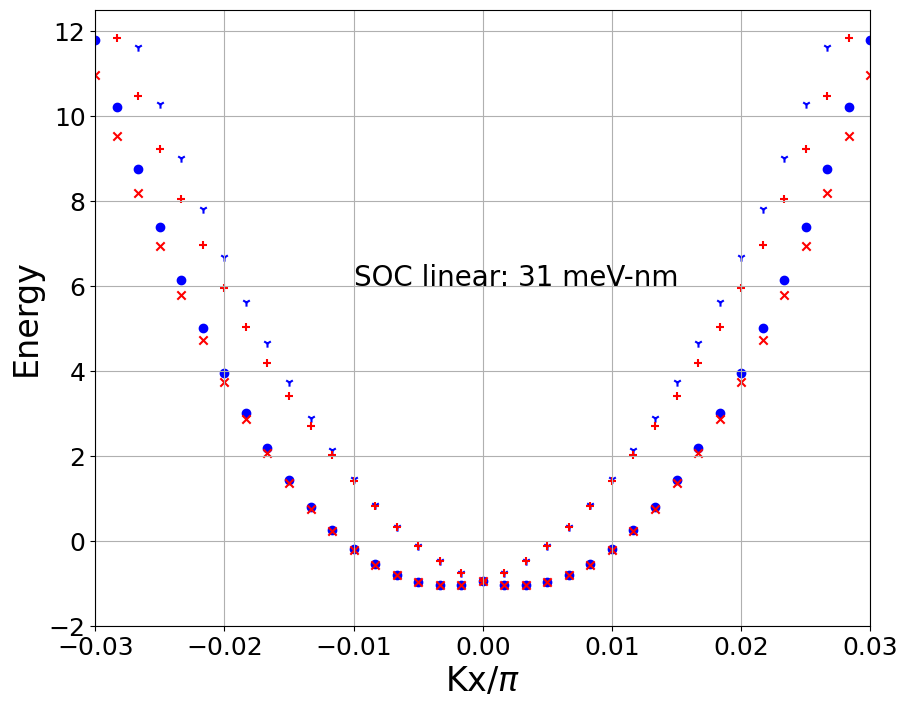

In [133]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
plt.scatter(KX/np.pi,Ep[:,1], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
plt.scatter(KX/np.pi,EpM[:,1], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.ylim(ymin=-2)
plt.ylim(ymax=12.5)

plt.xlim(xmax = 0.03,xmin=-0.03)

# Print parameters on the plot
plt.text(-0.01, 6, f'SOC linear: {ALPHAT} meV-nm', fontsize=20)

#plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

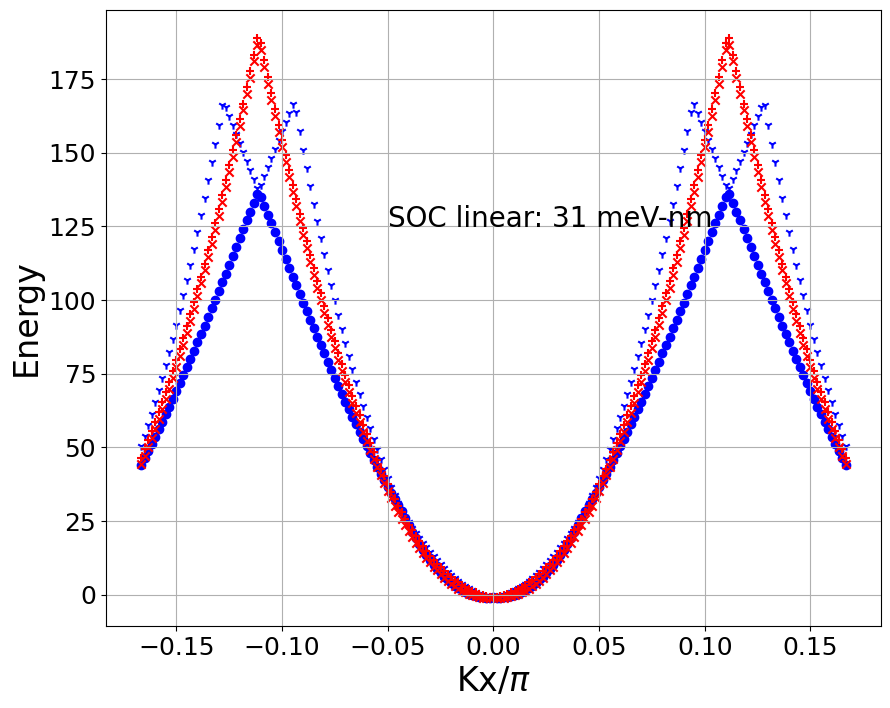

In [134]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
plt.scatter(KX/np.pi,Ep[:,1], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
plt.scatter(KX/np.pi,EpM[:,1], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

#plt.ylim(ymin=-2)
#plt.ylim(ymax=12.5)

#plt.xlim(xmax = 0.03,xmin=-0.03)

# Print parameters on the plot
plt.text(-0.05,125, f'SOC linear: {ALPHAT} meV-nm', fontsize=20)

#plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)